# 법안 분야 자동 분류 (C조 입법 영향 지도)

9주차 숫자 인식 실습의 신경망 구조를 법안 텍스트 분류에 그대로 적용한다.

| 9주차 숫자 인식 | 이 노트북 |
|---|---|
| 손글씨 이미지 28×28 = 784픽셀 | 법안 제안이유 → TF-IDF 벡터 3,000차원 |
| 정답 0~9 (10개) | 분야 1~9 (9개) |
| Dense 512 → 256 → Softmax 10 | Dense 512 → 256 → Softmax 9 |
| 학습·테스트 정확도, 오답 분석 | 같음 + 규칙 기반 기준선과 비교 |

**순서**: 1 데이터 불러오기 → 2 전처리 → 3 훈련·테스트 분리 → 4 규칙 기반 기준선 → 5 신경망 구성·학습 → 6 평가 → 7 법률명이 같은 법안 구간 비교 → 8 오답 분석 → 9 은닉층 구성 실험 → 10 676건 전체 예측·저장


## 0. 준비 (Colab 한글 글꼴)
그래프 한글이 깨지면 이 칸 실행 후 **런타임 → 세션 다시 시작** 한 번.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('/usr/share/fonts/truetype/nanum'):
    !apt-get -qq install fonts-nanum > /dev/null
    import matplotlib.font_manager as fm
    fm._load_fontmanager(try_read_cache=False)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.utils import to_categorical
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

plt.rcParams['font.family'] = 'NanumGothic' if os.path.exists('/usr/share/fonts/truetype/nanum') else plt.rcParams['font.family']
plt.rcParams['axes.unicode_minus'] = False

SEED = 42
np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()   # 다시 실행해도 같은 결과

FIELD = {1:'소방·화재', 2:'재난·안전관리', 3:'건축물 안전·노후·유지관리', 4:'주택 공급·임대·금융',
         5:'공동주택 관리·주거환경', 6:'정비사업·도시재생', 7:'도시계획·건축규제', 8:'주차·보행·교통', 9:'건설산업·기술·기타'}

I0000 00:00:1793960442.612575   14987 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793960442.652561   14987 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793960443.784065   14987 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. 데이터 불러오기
GitHub 저장소의 `data/` 폴더에서 읽는다. 저장소에 아직 없으면 파일 업로드 창이 뜬다.

In [3]:
BASE = 'https://raw.githubusercontent.com/cbnu-lawmap/law-impact-map/main/data/'

def load(name):
    try:
        return pd.read_csv(BASE + name, encoding='utf-8-sig', dtype={'BILL_NO': str})
    except Exception:
        if os.path.exists(name):
            return pd.read_csv(name, encoding='utf-8-sig', dtype={'BILL_NO': str})
        from google.colab import files
        print(name, '파일을 올려 주세요'); files.upload()
        return pd.read_csv(name, encoding='utf-8-sig', dtype={'BILL_NO': str})

lab = load('labels_300.csv')        # 라벨 300건 (LABEL 1~9, EXCLUDE, AMBIG)
allb = load('bills_summary.csv')    # 제안이유 676건 (예측 대상)
print('라벨', lab.shape, '/ 전체', allb.shape)
lab.head(3)

라벨 (300, 11) / 전체 (678, 7)


,NO,BILL_NO,BILL_NAME,COMMITTEE,LABEL,LABEL_NAME,BLDG,REASON,EXCLUDE,AMBIG,SUMMARY
0,1,2219282,시설물의 안전 및 유지관리에 관한 특별법 일부개정법률안,국토교통위원회,3,건축물 안전·노후·유지관리,N,내진성능 보강 권고 대상 확대,N,N,제안이유 및 주요내용 현행법은 내진성능평가를 받지 않은 내진설계 대상 시설물에 대하...
1,2,2218067,승강기 안전관리법 일부개정법률안,행정안전위원회,3,건축물 안전·노후·유지관리,N,건설공사용 승강기 사용 전 검사,N,N,제안이유 및 주요내용 현행법은 승강기의 설치 후 운행을 전제로 설치검사 및 안전검사...
2,3,2205921,도시 및 주거환경정비법 일부개정법률안,국토교통위원회,6,정비사업·도시재생,N,정비사업 개별홍보 금지 신고센터 의무화,N,N,제안이유 및 주요내용 현행법령은 시공자 선정 관련 비리 방지를 위하여 의무 개최되는...


## 2. 전처리
- 학습 제외(용어 정비형 2건) 빼기
- 제안이유의 머리말·공백 정리
- 법률명 뽑기 (규칙 기준선과 구간 분석에 사용)

In [4]:
import re

def clean(t):
    t = str(t)
    t = re.sub(r'^\s*제안이유\s*(및\s*주요내용)?', '', t)
    t = re.sub(r'\s+', ' ', t)
    return t.strip()

def law_name(n):
    n = re.sub(r'\s*(일부|전부)개정법률안.*|\s*법률안.*', '', str(n))
    return re.sub(r'\(.*?\)', '', n).strip()

df = lab[lab['EXCLUDE'] == 'N'].copy()
df['TEXT'] = df['SUMMARY'].map(clean)
df['LAW'] = df['BILL_NAME'].map(law_name)
print('학습에 쓰는 법안:', len(df), '건')
print(df['LABEL'].map(FIELD).value_counts())

학습에 쓰는 법안: 298 건
LABEL
주택 공급·임대·금융       65
소방·화재             43
정비사업·도시재생         42
도시계획·건축규제         32
재난·안전관리           30
공동주택 관리·주거환경      29
건축물 안전·노후·유지관리    26
주차·보행·교통          16
건설산업·기술·기타        15
Name: count, dtype: int64


## 3. 훈련·테스트 분리 (8:2, 분야 비율 유지)

In [5]:
tr, te = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df['LABEL'])
print('훈련', len(tr), '/ 테스트', len(te))

훈련 238 / 테스트 60


## 4. 규칙 기반 기준선 (1주차: 규칙 기반 AI)
사람이 정한 규칙: **"이 법률의 법안은 대부분 이 분야다"**. 훈련 데이터에서 법률별로 가장 많은 분야를 규칙으로 만들고, 처음 보는 법률은 가장 흔한 분야로 답한다.

In [6]:
rule = tr.groupby('LAW')['LABEL'].agg(lambda s: s.value_counts().idxmax()).to_dict()
default = tr['LABEL'].value_counts().idxmax()
te = te.copy()
te['RULE'] = te['LAW'].map(rule).fillna(default).astype(int)
acc_rule = accuracy_score(te['LABEL'], te['RULE'])
print('규칙 기반 테스트 정확도: %.3f' % acc_rule)

규칙 기반 테스트 정확도: 0.717


## 5. 신경망 (9주차 구조)
### 5-1. 입력 만들기: 글 → 숫자
이미지는 픽셀 밝기가 숫자였다. 글은 **TF-IDF**로 숫자로 바꾼다. 한국어는 띄어쓰기 단위가 길어서 글자 2~3개 묶음(n-gram)을 단어처럼 쓴다. 3,000개 묶음을 골라 법안 1건 = 숫자 3,000개.

In [7]:
vec = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 3), max_features=3000, sublinear_tf=True)
X_tr = vec.fit_transform(tr['TEXT']).toarray().astype('float32')
X_te = vec.transform(te['TEXT']).toarray().astype('float32')

# 정답 원-핫 인코딩 (분야 1~9 → 0~8 자리)
y_tr = to_categorical(tr['LABEL'] - 1, num_classes=9)
y_te = to_categorical(te['LABEL'] - 1, num_classes=9)
print(X_tr.shape, y_tr.shape)

(238, 3000) (238, 9)


### 5-2. 모델 구성·학습

In [8]:
def build(hidden=(512, 256), seed=SEED):
    tf.keras.utils.set_random_seed(seed)
    m = Sequential([Input(shape=(X_tr.shape[1],))])
    for h in hidden:
        m.add(Dense(h, activation='relu'))
    m.add(Dense(9, activation='softmax'))
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

model = build()
model.summary()
hist = model.fit(X_tr, y_tr, epochs=20, batch_size=16, validation_split=0.1, verbose=0)
print('마지막 epoch  학습 정확도 %.3f / 검증 정확도 %.3f' % (hist.history['accuracy'][-1], hist.history['val_accuracy'][-1]))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │     1,536,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,670,153 (6.37 MB)

 Trainable params: 1,670,153 (6.37 MB)

 Non-trainable params: 0 (0.00 B)

E0000 00:00:1793960445.781562   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


마지막 epoch  학습 정확도 1.000 / 검증 정확도 0.792


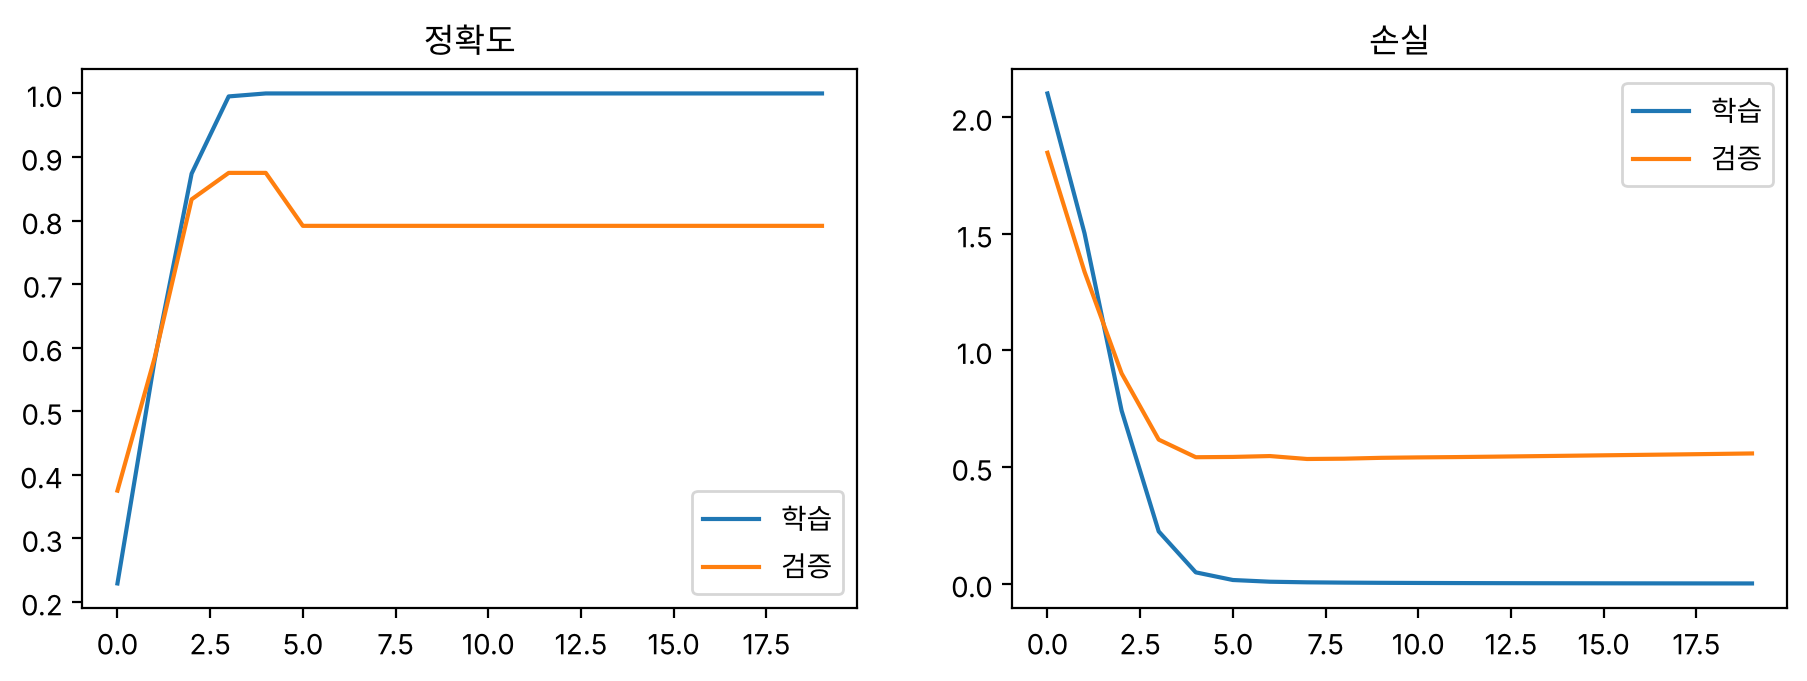

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist.history['accuracy'], label='학습'); ax[0].plot(hist.history['val_accuracy'], label='검증'); ax[0].set_title('정확도'); ax[0].legend()
ax[1].plot(hist.history['loss'], label='학습'); ax[1].plot(hist.history['val_loss'], label='검증'); ax[1].set_title('손실'); ax[1].legend()
plt.show()

## 6. 평가 (학습 vs 테스트 정확도로 과적합 확인)

In [10]:
acc_train = model.evaluate(X_tr, y_tr, verbose=0)[1]
acc_nn = model.evaluate(X_te, y_te, verbose=0)[1]
te['NN'] = model.predict(X_te, verbose=0).argmax(1) + 1
print('신경망  학습 정확도 %.3f / 테스트 정확도 %.3f' % (acc_train, acc_nn))
print('규칙 기반 테스트 정확도 %.3f' % acc_rule)
print()
print(classification_report(te['LABEL'], te['NN'], labels=list(FIELD), target_names=list(FIELD.values()), zero_division=0))

E0000 00:00:1793960451.356478   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


신경망  학습 정확도 0.979 / 테스트 정확도 0.733
규칙 기반 테스트 정확도 0.717

                precision    recall  f1-score   support

         소방·화재       0.80      0.89      0.84         9
       재난·안전관리       0.80      0.67      0.73         6
건축물 안전·노후·유지관리       0.60      0.60      0.60         5
   주택 공급·임대·금융       0.75      0.92      0.83        13
  공동주택 관리·주거환경       0.50      0.33      0.40         6
     정비사업·도시재생       0.80      0.89      0.84         9
     도시계획·건축규제       0.80      0.67      0.73         6
      주차·보행·교통       1.00      0.33      0.50         3
    건설산업·기술·기타       0.50      0.67      0.57         3

      accuracy                           0.73        60
     macro avg       0.73      0.66      0.67        60
  weighted avg       0.74      0.73      0.72        60



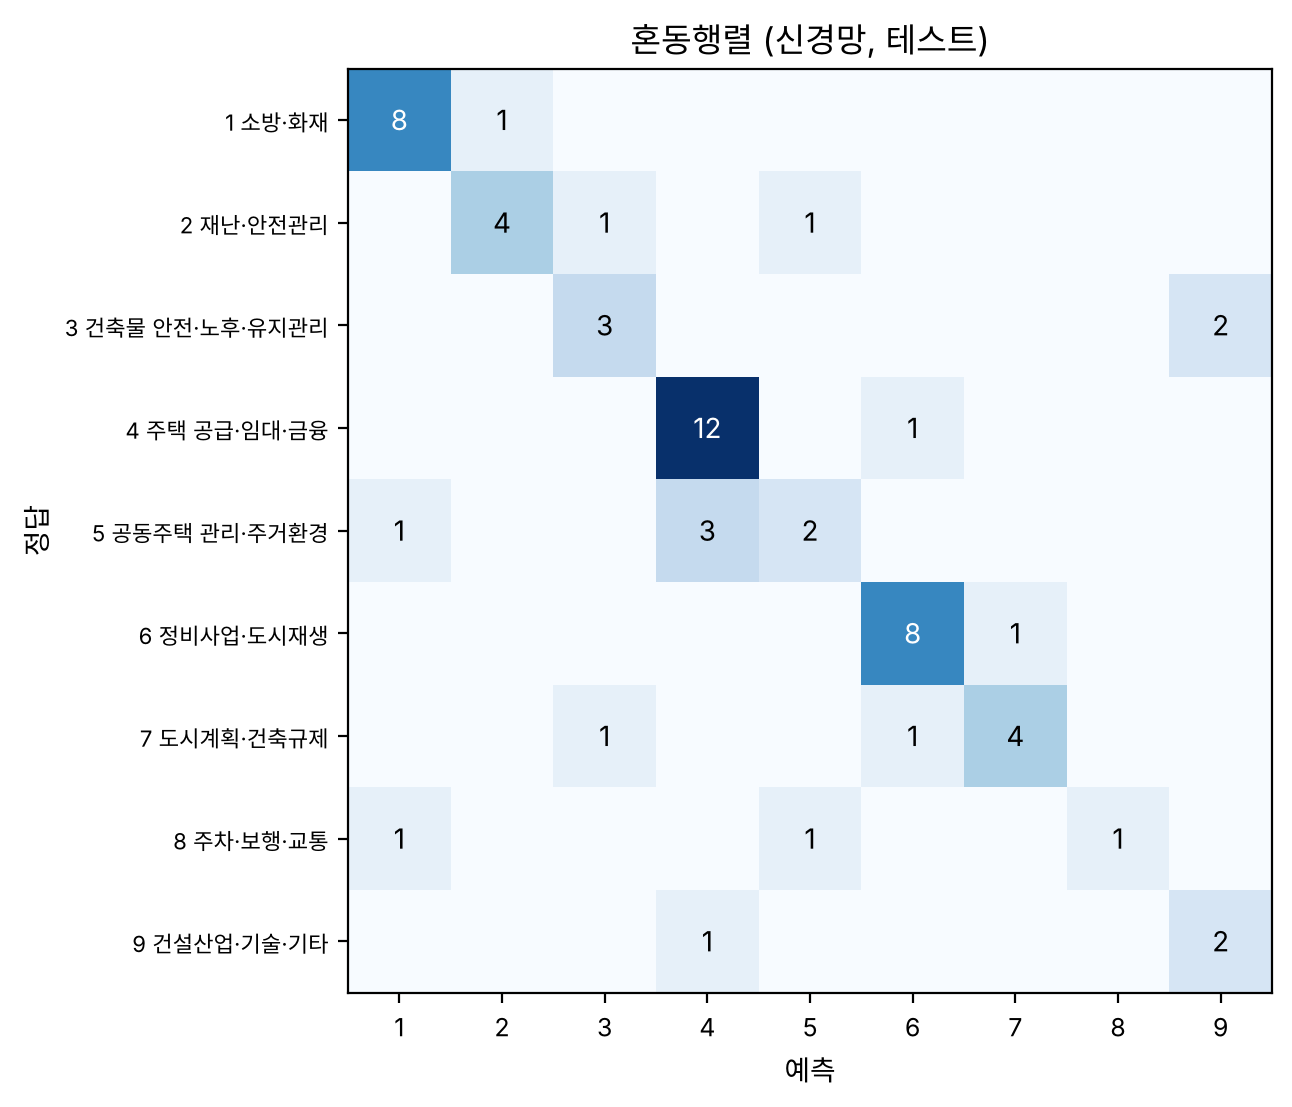

In [11]:
cm = confusion_matrix(te['LABEL'], te['NN'], labels=list(FIELD))
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(9)); ax.set_yticks(range(9))
ax.set_xticklabels(list(FIELD), fontsize=9); ax.set_yticklabels([f'{k} {v}' for k, v in FIELD.items()], fontsize=8)
for i in range(9):
    for j in range(9):
        if cm[i, j]: ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set_xlabel('예측'); ax.set_ylabel('정답'); ax.set_title('혼동행렬 (신경망, 테스트)')
plt.show()

## 7. 법률명이 같아도 분야가 갈리는 법안 구간
규칙 기반은 법률명만 보므로, **한 법률 안에서 분야가 여러 개로 갈리는 법률**(예: 주택법)에서 약하다. 이 구간에서 두 방법을 따로 비교한다.

In [12]:
mixed = df.groupby('LAW')['LABEL'].nunique()
mixed_laws = mixed[mixed > 1].index
print('분야가 갈리는 법률:', list(mixed_laws))

seg = te['LAW'].isin(mixed_laws)
res = pd.DataFrame({
    '구간': ['전체', '분야가 갈리는 법률', '분야가 하나인 법률'],
    '건수': [len(te), seg.sum(), (~seg).sum()],
    '규칙 기반': [accuracy_score(te.LABEL, te.RULE), accuracy_score(te[seg].LABEL, te[seg].RULE), accuracy_score(te[~seg].LABEL, te[~seg].RULE)],
    '신경망': [accuracy_score(te.LABEL, te.NN), accuracy_score(te[seg].LABEL, te[seg].NN), accuracy_score(te[~seg].LABEL, te[~seg].NN)],
}).round(3)
res

분야가 갈리는 법률: ['건설기술 진흥법', '건축물관리법', '건축법', '공공주택 특별법', '공동주택관리법', '도시 및 주거환경정비법', '민간임대주택에 관한 특별법', '승강기 안전관리법', '장기공공임대주택 입주자 삶의 질 향상 지원법', '주차장법', '주택도시기금법', '주택법']


,구간,건수,규칙 기반,신경망
0,전체,60,0.717,0.733
1,분야가 갈리는 법률,35,0.686,0.629
2,분야가 하나인 법률,25,0.760,0.880


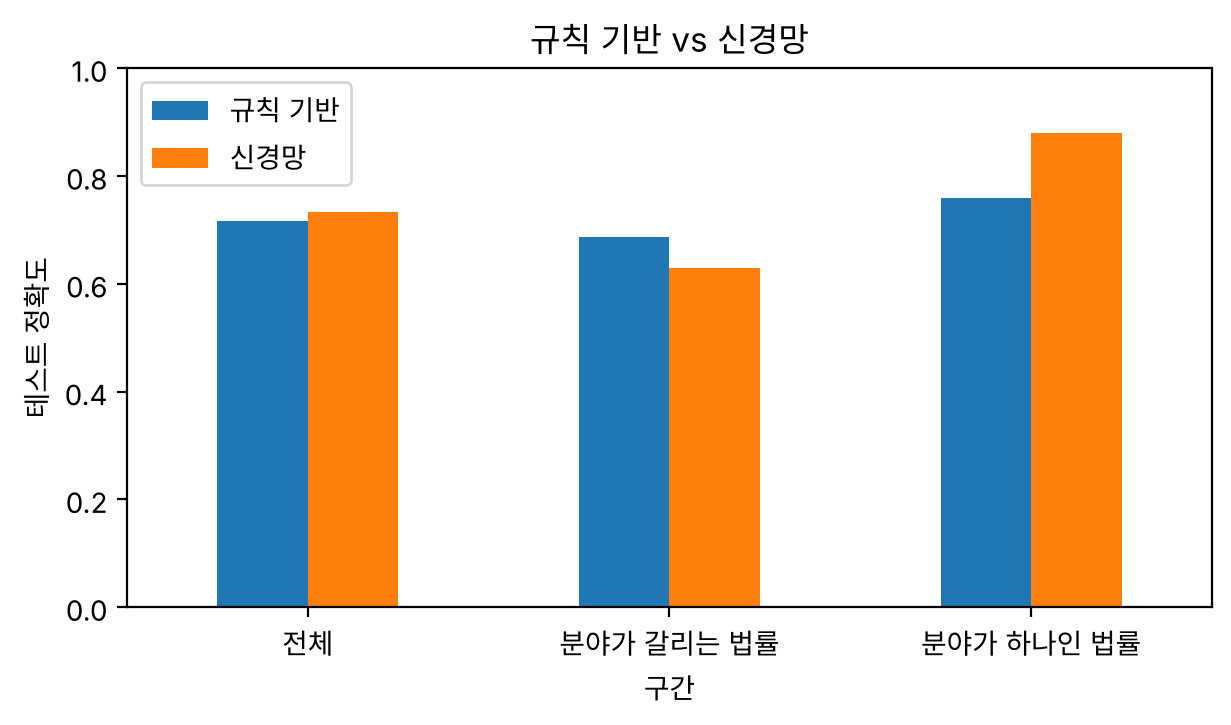

In [13]:
ax = res.set_index('구간')[['규칙 기반', '신경망']].plot.bar(figsize=(7, 3.5), rot=0, ylim=(0, 1))
ax.set_ylabel('테스트 정확도'); ax.set_title('규칙 기반 vs 신경망')
plt.show()

### 7-2. 테스트 60건 한 번만으로는 숫자가 흔들린다 → 분할을 10번 바꿔 평균
훈련·테스트를 무작위로 10번 다시 나눠 같은 비교를 반복한다. 보고서에는 이 평균을 쓴다.

In [14]:
rep = []
for r in range(10):
    a, b = train_test_split(df, test_size=0.2, random_state=100 + r, stratify=df['LABEL'])
    rl = a.groupby('LAW')['LABEL'].agg(lambda s: s.value_counts().idxmax()).to_dict()
    dflt = a['LABEL'].value_counts().idxmax()
    rule_p = b['LAW'].map(rl).fillna(dflt).astype(int)
    v = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 3), max_features=3000, sublinear_tf=True)
    xa = v.fit_transform(a['TEXT']).toarray().astype('float32'); xb = v.transform(b['TEXT']).toarray().astype('float32')
    tf.keras.utils.set_random_seed(SEED + r)
    m = Sequential([Input(shape=(xa.shape[1],)), Dense(512, activation='relu'), Dense(256, activation='relu'), Dense(9, activation='softmax')])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    m.fit(xa, to_categorical(a['LABEL'] - 1, 9), epochs=20, batch_size=16, verbose=0)
    nn_p = m.predict(xb, verbose=0).argmax(1) + 1
    sg = b['LAW'].isin(mixed_laws).values
    rep.append({'분할': r + 1,
                '규칙_전체': accuracy_score(b.LABEL, rule_p), '신경망_전체': accuracy_score(b.LABEL, nn_p),
                '규칙_갈리는법률': accuracy_score(b.LABEL[sg], rule_p[sg]), '신경망_갈리는법률': accuracy_score(b.LABEL[sg], nn_p[sg]),
                '규칙_하나인법률': accuracy_score(b.LABEL[~sg], rule_p[~sg]), '신경망_하나인법률': accuracy_score(b.LABEL[~sg], nn_p[~sg])})
rep = pd.DataFrame(rep)
summary = rep.drop(columns='분할').agg(['mean', 'std']).T.round(3)
summary.columns = ['평균', '표준편차']
summary

E0000 00:00:1793960456.905408   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793960465.993446   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793960471.018378   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793960479.706589   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793960488.439792   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


E0000 00:00:1793960493.996591   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


,평균,표준편차
규칙_전체,0.757,0.069
신경망_전체,0.795,0.057
규칙_갈리는법률,0.737,0.090
신경망_갈리는법률,0.776,0.087
규칙_하나인법률,0.789,0.084
신경망_하나인법률,0.823,0.054


## 8. 오답 분석 (9주차 05와 같은 방식)

In [15]:
wrong = te[te['NN'] != te['LABEL']].copy()
wrong['정답'] = wrong['LABEL'].map(FIELD); wrong['예측'] = wrong['NN'].map(FIELD); wrong['규칙'] = wrong['RULE'].map(FIELD)
wrong['제안이유(앞부분)'] = wrong['TEXT'].str[:80]
print('신경망 오답', len(wrong), '건 / 그중 애매 표시', (wrong['AMBIG'] == 'Y').sum(), '건')
pd.set_option('display.max_colwidth', 90)
wrong[['NO', 'BILL_NAME', '정답', '예측', '규칙', '제안이유(앞부분)']]

신경망 오답 16 건 / 그중 애매 표시 0 건


,NO,BILL_NAME,정답,예측,규칙,제안이유(앞부분)
73,74,소방기본법 일부개정법률안,소방·화재,재난·안전관리,소방·화재,현행법은 소방기술 및 소방산업의 국제화사업에 관한 근거를 두어 소방기술 및 소방산업의 국제경쟁력과 국제적 통용성을 높이기 위한 사업을 추진하도록
23,24,풍수해ㆍ지진재해보험법 일부개정법률안,재난·안전관리,공동주택 관리·주거환경,주택 공급·임대·금융,과도한 형벌규정으로 인한 민간 경제활동의 어려움을 경감하기 위하여 풍수해ㆍ지진재해보험사업의 회계를 다른 회계와 구분회계처리하지 않은 보험사업자에
169,170,공동주택관리법 일부개정법률안,주차·보행·교통,공동주택 관리·주거환경,공동주택 관리·주거환경,최근 공동주택 내에서 자동차의 주차 또는 통행을 방해하는 등 주차질서를 위반하는 행위가 급격히 증가하고 있음에도 불구하고 현행법에서는 해당 행위
273,274,승강기 안전관리법 일부개정법률안,건설산업·기술·기타,주택 공급·임대·금융,건축물 안전·노후·유지관리,"최근 민생과 밀접한 분야에서 부당한 담합행위가 끊이지 않고 발생하고 있으며, 일부 사업자의 경우 공정거래위원회의 제재에도 불구하고 담합을 반복하"
98,99,공동주택관리법 일부개정법률안,공동주택 관리·주거환경,소방·화재,공동주택 관리·주거환경,최근 아파트 등 공동주택의 공용공간을 일부 입주자 개인의 창고처럼 사유화하는 행위로 입주자간 분쟁이 발생하고 있음. 현행법에 따라 화재 등 긴급
158,159,건설기술 진흥법 일부개정법률안,건축물 안전·노후·유지관리,건설산업·기술·기타,건설산업·기술·기타,"시ㆍ도지사와 국토안전관리원에 건설현장 점검권한, 사고조사 권한 등을 부여하여 해당 기관의 적극적인 안전관리를 통해 안전사고 예방에 기여하고자 하"
129,130,건축법 일부개정법률안,도시계획·건축규제,건축물 안전·노후·유지관리,도시계획·건축규제,"현행법에 따라 건축허가 업무 등의 전산처리를 위한 시스템(건축행정시스템)이 운영되고 있고, 시스템에 따라 처리된 전산자료를 이용하려는 자는 관계"
35,36,공공주택 특별법 일부개정법률안,주택 공급·임대·금융,정비사업·도시재생,주택 공급·임대·금융,현행법은 공공주택지구 조성을 위해 개발제한구역을 해제하는 경우 훼손지 복구계획 수립 대상 사업과 범위가 과도하여 소규모 지구에 부담이 발생하고
286,287,주택법 일부개정법률안,공동주택 관리·주거환경,주택 공급·임대·금융,주택 공급·임대·금융,"현행법에 따르면 구조적으로 오랫동안 유지ㆍ관리될 수 있는 내구성을 갖추고, 입주자의 필요에 따라 내부 구조를 쉽게 변경할 수 있는 가변성과 수리"
1,2,승강기 안전관리법 일부개정법률안,건축물 안전·노후·유지관리,건설산업·기술·기타,건축물 안전·노후·유지관리,"현행법은 승강기의 설치 후 운행을 전제로 설치검사 및 안전검사 제도를 규정하고 있으나, 건설공사 현장에서 근로자 또는 자재의 운반을 위하여 임시"


## 9. 은닉층 구성 실험 (4주차: 신경망 구조 설계)
같은 데이터로 은닉층만 바꿔 3번씩 학습해 평균 테스트 정확도를 본다.

In [16]:
rows = []
for hidden in [(128,), (256, 128), (512, 256), (512, 256, 128)]:
    accs = []
    for s in range(3):
        m = build(hidden, seed=SEED + s)
        m.fit(X_tr, y_tr, epochs=20, batch_size=16, verbose=0)
        accs.append(m.evaluate(X_te, y_te, verbose=0)[1])
    rows.append({'은닉층': str(hidden), '평균 테스트 정확도': round(np.mean(accs), 3), '최저': round(min(accs), 3), '최고': round(max(accs), 3)})
pd.DataFrame(rows)

E0000 00:00:1793960500.612720   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793960506.139398   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793960513.058220   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793960521.186004   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793960530.169329   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793960539.708346   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1793960544.738039   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


,은닉층,평균 테스트 정확도,최저,최고
0,"(128,)",0.794,0.783,0.800
1,"(256, 128)",0.789,0.783,0.800
2,"(512, 256)",0.778,0.767,0.783
3,"(512, 256, 128)",0.778,0.750,0.800


## 10. 676건 전체 분야 예측·저장
지도 화면에서 법안을 분야별로 거를 때 쓰는 파일. 300건 라벨 전체로 다시 학습한 뒤 예측한다.

In [17]:
X_all = vec.fit_transform(df['TEXT']).toarray().astype('float32')
y_all = to_categorical(df['LABEL'] - 1, num_classes=9)
tf.keras.utils.set_random_seed(SEED)
final = Sequential([Input(shape=(X_all.shape[1],)), Dense(512, activation='relu'), Dense(256, activation='relu'), Dense(9, activation='softmax')])
final.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
final.fit(X_all, y_all, epochs=20, batch_size=16, verbose=0)

pred = allb.copy()
pred['TEXT'] = pred['SUMMARY'].fillna('').map(clean)
prob = final.predict(vec.transform(pred['TEXT']).toarray().astype('float32'), verbose=0)
pred['FIELD_PRED'] = prob.argmax(1) + 1
pred['FIELD_NAME'] = pred['FIELD_PRED'].map(FIELD)
pred['CONF'] = prob.max(1).round(3)
known = lab.set_index('BILL_NO')['LABEL']
pred['FIELD_LABEL'] = pred['BILL_NO'].map(known)          # 사람이 확인한 라벨이 있으면 함께 기록
out = pred[['BILL_NO', 'BILL_NAME', 'FIELD_PRED', 'FIELD_NAME', 'CONF', 'FIELD_LABEL']]
out.to_csv('bills_field_pred.csv', index=False, encoding='utf-8-sig')
print(out['FIELD_NAME'].value_counts())
print('확신도 0.5 미만:', (out['CONF'] < 0.5).sum(), '건 → 지도에서 "분야 불확실" 표시 후보')

FIELD_NAME
주택 공급·임대·금융       147
소방·화재             109
정비사업·도시재생          99
공동주택 관리·주거환경       74
도시계획·건축규제          68
재난·안전관리            68
건축물 안전·노후·유지관리     53
건설산업·기술·기타         31
주차·보행·교통           29
Name: count, dtype: int64
확신도 0.5 미만: 28 건 → 지도에서 "분야 불확실" 표시 후보


E0000 00:00:1793960550.407603   14987 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


## 결과 정리 (보고서용)
| 항목 | 값 |
|---|---|
| 학습 데이터 | 라벨 300건 중 298건 (용어 정비형 2건 제외), 훈련 238 / 테스트 60 |
| 입력 | 제안이유 글자 2~3묶음 TF-IDF 3,000차원 |
| 모델 | Dense 512 → 256 (ReLU) → Softmax 9, Adam, 20 epoch |
| 비교 | 규칙 기반(법률명 → 분야) vs 신경망, 전체 / 분야가 갈리는 법률 구간 |

※ 위 숫자 칸은 실행 결과를 보고 채운다.